# Seminar 3: Exploratory Data Analysis in Python 
---
Boris Gerát - 3.11

LINK: Download folder for this notebook

In [ ]:
#%pip install numpy pandas seaborn matplotlib

**TASK** Import the libraries. If you don't have them installed yet, use the code cell above to install them.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import random

### PART 1: Read the data and understand its structure

**TASK** Load the data named `AmesHousing.csv` from the data folder. Hint: Use the pandas function `read_csv`.

In [3]:
houseData = pd.read_csv("/Users/borisgerat/Documents/PhD/teaching/dataPython/seminars/fourth_3_11/data/archive (5)/AmesHousing.csv")

**TASK** Explore the dataset. Show the whole dataset, its beginning and its end. Hint: cheatsheet

In [7]:
print(houseData.tail()) 


      Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
2925   2926  923275080           80        RL          37.0      7937   Pave   
2926   2927  923276100           20        RL           NaN      8885   Pave   
2927   2928  923400125           85        RL          62.0     10441   Pave   
2928   2929  924100070           20        RL          77.0     10010   Pave   
2929   2930  924151050           60        RL          74.0      9627   Pave   

     Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
2925   NaN       IR1          Lvl  ...         0     NaN  GdPrv          NaN   
2926   NaN       IR1          Low  ...         0     NaN  MnPrv          NaN   
2927   NaN       Reg          Lvl  ...         0     NaN  MnPrv         Shed   
2928   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
2929   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   

     Misc Val Mo Sold Yr Sold Sale Typ

**TASK** Print the names of the columns, their data types and the shape of the dataset. Hint: cheatsheet

In [31]:
print(houseData.columns) 
print(houseData.dtypes) 
print(houseData.shape)

Index(['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area',
       'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities',
       'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual',
       'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style',
       'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type',
       'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual',
       'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1',
       'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
       'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF',
       '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr',
       'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional',
       'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt',
      

**TASK** Print the last 10 data types of the columns. Hint: Slicing

In [14]:
print(houseData.dtypes[-10:])

Pool Area         int64
Pool QC             str
Fence               str
Misc Feature        str
Misc Val          int64
Mo Sold           int64
Yr Sold           int64
Sale Type           str
Sale Condition      str
SalePrice         int64
dtype: object


**TASK** Now do the same thing with a for loop. Is the output the same? Hint: Check the type of the data

In [33]:
for i in houseData.dtypes[-10:]: 
    print(i)

int64
str
str
str
int64
int64
int64
str
str
int64


**Question** Are they the same? If not, why? Hint: Check the data type of the objects `houseData` and `houseData.dtypes`.

In [35]:
print(type(houseData)) 
print(type(houseData.dtypes))

<class 'pandas.DataFrame'>
<class 'pandas.Series'>


**TASK** Can you get the same output with a for loop? Hint: Loop over two elements at once (index and value)

In [43]:
for idx, i in houseData.dtypes[-10:].items(): 
    print (idx, i)

Pool Area int64
Pool QC str
Fence str
Misc Feature str
Misc Val int64
Mo Sold int64
Yr Sold int64
Sale Type str
Sale Condition str
SalePrice int64


### PART 2 - Splitting the columns based on their data type

**TASK** Print the dtypes of the columns one more time

In [44]:
print(houseData.dtypes)

Order               int64
PID                 int64
MS SubClass         int64
MS Zoning             str
Lot Frontage      float64
                   ...   
Mo Sold             int64
Yr Sold             int64
Sale Type             str
Sale Condition        str
SalePrice           int64
Length: 82, dtype: object


**TASK** Let's save the `quant` columns and the `string` columns in two lists. Hint: Use a for loop with one rule

In [58]:
quantCol = [i for i in houseData.columns if houseData.dtypes[i] != "str"] 
stringCol = [i for i in houseData.columns if houseData.dtypes[i] == "str"] 
print(quantCol)
print(stringCol)

['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'SalePrice']
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Elect

**TASK** Use the quant columns you have collected to filter the dataset

In [63]:
quantPart = houseData[quantCol] 
print(quantPart.dtypes)

Order                int64
PID                  int64
MS SubClass          int64
Lot Frontage       float64
Lot Area             int64
Overall Qual         int64
Overall Cond         int64
Year Built           int64
Year Remod/Add       int64
Mas Vnr Area       float64
BsmtFin SF 1       float64
BsmtFin SF 2       float64
Bsmt Unf SF        float64
Total Bsmt SF      float64
1st Flr SF           int64
2nd Flr SF           int64
Low Qual Fin SF      int64
Gr Liv Area          int64
Bsmt Full Bath     float64
Bsmt Half Bath     float64
Full Bath            int64
Half Bath            int64
Bedroom AbvGr        int64
Kitchen AbvGr        int64
TotRms AbvGrd        int64
Fireplaces           int64
Garage Yr Blt      float64
Garage Cars        float64
Garage Area        float64
Wood Deck SF         int64
Open Porch SF        int64
Enclosed Porch       int64
3Ssn Porch           int64
Screen Porch         int64
Pool Area            int64
Misc Val             int64
Mo Sold              int64
Y

**TASK** Let's display a sample of 10 rows from the `Overall Qual` column. Hint: Use the method `sample`

In [68]:
houseData['Overall Qual'].sample(10)

60      8
141     5
1872    7
2113    7
2903    1
271     7
1855    5
1130    6
1800    8
284     5
Name: Overall Qual, dtype: int64

**TASK** Display how many rows have each quality ranking, in ascending order. Hint: Use the method `value_counts`

In [ ]:
quantPart['Overall Qual'].value_counts(ascending=True) 
quantPart

Overall Qual
1       4
2      13
10     31
3      40
9     107
4     226
8     350
7     602
6     732
5     825
Name: count, dtype: int64

**TASK** Now use a `histogram` to display `Overall Qual`. Hint: Use it as a method

<Axes: >

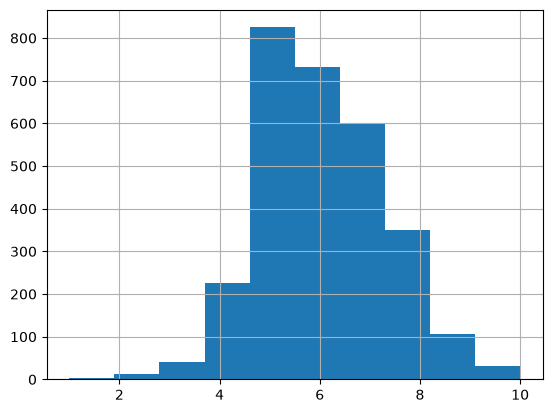

In [71]:
quantPart['Overall Qual'].hist()

### PART 3 - Missing Data

**TASK** Display the missing values. Hint: Use the method `isna`

In [72]:
houseData.isna()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,False,False,False,False,False,False,False,True,False,False,...,False,True,True,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,True,False,False,...,False,True,False,True,False,False,False,False,False,False
2,False,False,False,False,False,False,False,True,False,False,...,False,True,True,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,False,...,False,True,True,True,False,False,False,False,False,False
4,False,False,False,False,False,False,False,True,False,False,...,False,True,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,False,False,False,False,False,False,False,True,False,False,...,False,True,False,True,False,False,False,False,False,False
2926,False,False,False,False,True,False,False,True,False,False,...,False,True,False,True,False,False,False,False,False,False
2927,False,False,False,False,False,False,False,True,False,False,...,False,True,False,False,False,False,False,False,False,False
2928,False,False,False,False,False,False,False,True,False,False,...,False,True,True,True,False,False,False,False,False,False


**TASK** Now sum the missing values and show the 20 columns with the most missing values

In [77]:
houseData.isna().sum().sort_values(ascending=True)[-20:]

Bsmt Half Bath       2
Bsmt Full Bath       2
Mas Vnr Area        23
Bsmt Qual           80
Bsmt Cond           80
BsmtFin Type 1      80
BsmtFin Type 2      81
Bsmt Exposure       83
Garage Type        157
Garage Finish      159
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Lot Frontage       490
Fireplace Qu      1422
Mas Vnr Type      1775
Fence             2358
Alley             2732
Misc Feature      2824
Pool QC           2917
dtype: int64

**TASK** Remove columns with no missing values

In [81]:
missing = houseData.isna().sum() 
missing = missing[missing >0] 
print(len(missing[missing == 0]))

0


**TASK** Plot the top 10 columns with the most missing data in a bar chart. Hint: Use a method as a way to plot

Electrical           1
Garage Cars          1
BsmtFin SF 1         1
Garage Area          1
BsmtFin SF 2         1
Bsmt Unf SF          1
Total Bsmt SF        1
Bsmt Half Bath       2
Bsmt Full Bath       2
Mas Vnr Area        23
Bsmt Qual           80
Bsmt Cond           80
BsmtFin Type 1      80
BsmtFin Type 2      81
Bsmt Exposure       83
Garage Type        157
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Lot Frontage       490
Fireplace Qu      1422
Mas Vnr Type      1775
Fence             2358
Alley             2732
Misc Feature      2824
Pool QC           2917
dtype: int64


<Axes: >

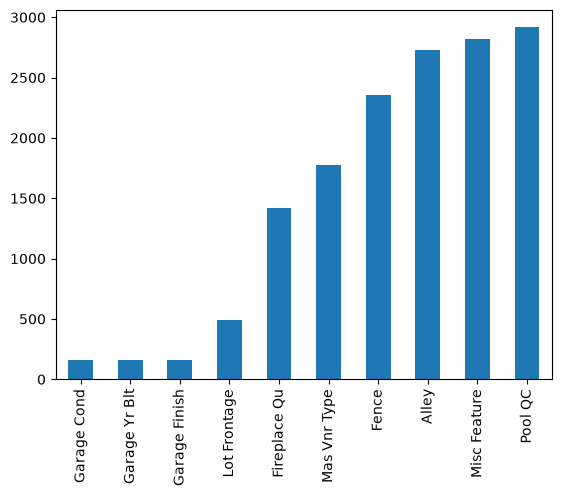

In [86]:
missing = missing.sort_values(ascending=True)
print(missing) 
missing[-10:].plot.bar()

### PART 4 - Aggregation

**TASK** Aggregate the price of the houses by their quality and plot it. Hint: Use the `groupby` method

Overall Qual
1      48725.000000
2      52325.307692
3      83185.975000
4     106485.097345
5     134752.516364
6     162130.318306
7     205025.760797
8     270913.594286
9     368336.766355
10    450217.322581
Name: SalePrice, dtype: float64


<Axes: xlabel='Overall Qual'>

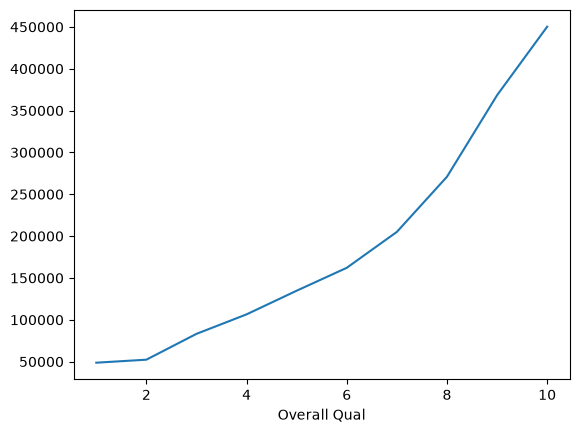

In [94]:
subset = houseData.groupby('Overall Qual')['SalePrice'].mean()
print(subset) 
subset.plot()


**TASK** Display overall condition and price based on overall quality. Show the mean, max and min of the columns. Hint: Use the `agg` method

In [97]:
houseData.groupby('Overall Qual')[['SalePrice', 'Overall Cond']].agg(['mean','max','min'])

SalePrice                 Overall Cond        
                       mean     max     min         mean max min
Overall Qual                                                    
1              48725.000000   81500   13100     3.000000   5   1
2              52325.307692   82000   12789     3.538462   5   1
3              83185.975000  139600   37900     4.475000   8   1
4             106485.097345  256000   34900     5.446903   9   1
5             134752.516364  301600   55993     5.824242   9   1
6             162130.318306  415000   76000     5.795082   9   2
7             205025.760797  383970   82500     5.430233   9   3
8             270913.594286  538000  122000     5.205714   9   4
9             368336.766355  611657  150000     4.953271   5   2
10            450217.322581  755000  160000     5.290323   9   5

**TASK** Calculate the average sale price for each street

In [100]:
houseData.groupby("Street")['SalePrice'].mean()

Street
Grvl    106663.333333
Pave    181100.923920
Name: SalePrice, dtype: float64

**TASK** Calculate the average `SalePrice` for the `Grvl` street

In [102]:
houseData[houseData['Street'] == "Grvl"].groupby("Street")['SalePrice'].mean()

Street
Grvl    106663.333333
Name: SalePrice, dtype: float64

**TASK** Calculate the average house price for the `Grvl` street, but only for sale prices higher than `100k`

In [109]:
houseData[(houseData['Street'] == "Grvl") & (houseData['SalePrice'] > 100000)].groupby("Street")['SalePrice'].mean()

Street
Grvl    159670.8
Name: SalePrice, dtype: float64

### PART 5 - Filtering

**TASK** Find rows where `SalePrice` is under 200k and `Sale Condition` is Normal

In [ ]:
houseData[(houseData['SalePrice'] < 200000) & (houseData['Sale Condition'] == "Normal")]

1       105000
2       172000
4       189900
5       195500
7       191500
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 1749, dtype: int64

**TASK** Now switch the condition to `or`

In [ ]:
houseData[(houseData['SalePrice'] < 200000) | (houseData['Sale Condition'] == "Abnorml")]


np.float64(141813.52821997105)

**TASK** Filter observations that have a larger area on `1st Flr SF` than on `2nd Flr SF`

In [132]:
houseData[houseData['1st Flr SF'] > houseData['2nd Flr SF']]

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2924,2925,923251180,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml,131000
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000


### PART 6 - Dates in Pandas

**TASK** Put the date into datetime format and set it as the index in the pandas DataFrame below. Hint: Use the function `to_datetime`

In [152]:
df = pd.DataFrame({
    'date':   ['2026-01-05', '2026-01-06', '2026-01-13', '2026-02-03', '2026-02-17', 'error'],
    'volume': [100, 120, 90, 150, 80, 45],
})
df

,date,volume
0,2026-01-05,100
1,2026-01-06,120
2,2026-01-13,90
3,2026-02-03,150
4,2026-02-17,80
5,error,45


In [150]:
df['date'] = pd.to_datetime(df['date'], errors="coerce") 
print(df)

        date  volume
0 2026-01-05     100
1 2026-01-06     120
2 2026-01-13      90
3 2026-02-03     150
4 2026-02-17      80
5        NaT      45


**TASK** Resample the index in the DataFrame below into quarterly and yearly

In [162]:
idx = pd.date_range('2025-01-31', periods=24, freq='ME')   # 24 month-ends
m = pd.DataFrame({
    'price':  np.linspace(100, 123, 24).round(1),
    'volume': np.arange(1, 25) * 10,
}, index=idx)
m.head()

,price,volume
2025-01-31,100.0,10
2025-02-28,101.0,20
2025-03-31,102.0,30
2025-04-30,103.0,40
2025-05-31,104.0,50


In [166]:
mQuart = m.resample("QE").sum()  
print(mQuart) 
mYear = m.resample("YE").mean() 
print(mYear)


            price  volume
2025-03-31  303.0      60
2025-06-30  312.0     150
2025-09-30  321.0     240
2025-12-31  330.0     330
2026-03-31  339.0     420
2026-06-30  348.0     510
2026-09-30  357.0     600
2026-12-31  366.0     690
            price  volume
2025-12-31  105.5    65.0
2026-12-31  117.5   185.0
